# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Haffel
- **Email:** ds009b6y1168@student.devacademy.id
- **ID Dicoding:** DS009B6Y1168

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana keterlambatan waktu pengiriman (selisih tanggal estimasi dan tanggal tiba aktual) memengaruhi tingkat kepuasan pelanggan yang tercermin pada distribusi skor ulasan (*review score*) di negara bagian São Paulo (SP) sepanjang tahun 2018?
- **Pertanyaan 2:** Kategori produk apa yang menghasilkan total nilai penjualan (*revenue*) tertinggi dan terendah selama periode akhir tahun (Kuartal 4: Oktober - Desember) pada tahun 2017?
- **Pertanyaan 3:** Metode pembayaran apa yang paling sering digunakan oleh pelanggan dan berapa rata-rata nilai transaksinya (*average order value*) selama tahun 2018?

## Import Semua Packages/Library yang Digunakan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

sns.set_theme(style="darkgrid")
warnings.filterwarnings("ignore")

## Data Wrangling

### Gathering Data

#### Load df ...

In [3]:
orders_df = pd.read_csv("orders_dataset.csv")
reviews_df = pd.read_csv("order_reviews_dataset.csv")
customers_df = pd.read_csv("customers_dataset.csv")
items_df = pd.read_csv("order_items_dataset.csv")
products_df = pd.read_csv("products_dataset.csv")
translation_df = pd.read_csv("product_category_name_translation.csv")
payments_df = pd.read_csv("order_payments_dataset.csv")

print("Seluruh Dataset Berhasil Dimuat.")

print("1. Cuplikan Data Pesanan (Orders):")
display(orders_df.head(3))

print("\n2. Cuplikan Data Ulasan (Reviews):")
display(reviews_df.head(3))

print("\n3. Cuplikan Data Pembayaran (Payments):")
display(payments_df.head(3))

print("\n4. Cuplikan Data Produk (Products):")
display(products_df.head(3))

Seluruh Dataset Berhasil Dimuat.
1. Cuplikan Data Pesanan (Orders):


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00



2. Cuplikan Data Ulasan (Reviews):


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24



3. Cuplikan Data Pembayaran (Payments):


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71



4. Cuplikan Data Produk (Products):


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


**Insight:** (Opsional)

1. **Tabel Orders:** Format tanggal pada kolom seperti `order_purchase_timestamp` dan `order_delivered_customer_date` masih berupa teks standar (YYYY-MM-DD HH:MM:SS). Kolom-kolom ini siap untuk dikonversi menjadi tipe data `datetime` agar kita bisa menghitung selisih hari pengiriman.
2. **Tabel Reviews:** Terlihat jelas adanya nilai `NaN` (kosong) pada kolom `review_comment_title` dan `review_comment_message`. Hal ini membuktikan bahwa banyak pelanggan hanya memberikan *rating* berupa angka (skor 1-5) tanpa menuliskan ulasan teks. Data ini perlu ditangani pada tahap *Cleaning*.
3. **Tabel Payments:** Data transaksi memuat informasi yang sangat rinci, termasuk jenis pembayaran (`payment_type` seperti *credit_card*) hingga jumlah cicilan (`payment_installments`) dan nominalnya (`payment_value`). Struktur ini sudah sangat ideal untuk dieksplorasi guna menjawab pertanyaan bisnis ketiga.
4. **Tabel Products:** Nilai pada kolom kategori produk (`product_category_name`) menggunakan bahasa Portugis (contoh: *perfumaria*, *artes*, *esporte_lazer*). Ini memvalidasi keputusan kita sebelumnya untuk melakukan *merge* dengan tabel `translation_df` agar nama kategori diubah ke bahasa Inggris sehingga lebih mudah dipahami oleh pembaca laporan.

### Assessing Data

#### Identifying ... problem

In [4]:
print("Missing values pada orders_df:\n", orders_df.isnull().sum()[orders_df.isnull().sum() > 0])
print("\nMissing values pada reviews_df:\n", reviews_df.isnull().sum()[reviews_df.isnull().sum() > 0])
print("\nMissing values pada payments_df:\n", payments_df.isnull().sum())

print("\nTipe data kolom tanggal pada orders_df:")
print(orders_df[['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']].dtypes)

print("\nJumlah duplikat pada orders_df:", orders_df.duplicated().sum())
print("Jumlah duplikat pada reviews_df:", reviews_df.duplicated().sum())
print("Jumlah duplikat pada payments_df:", payments_df.duplicated().sum())

Missing values pada orders_df:
 order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Missing values pada reviews_df:
 review_comment_title      87656
review_comment_message    58247
dtype: int64

Missing values pada payments_df:
 order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Tipe data kolom tanggal pada orders_df:
order_purchase_timestamp         object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

Jumlah duplikat pada orders_df: 0
Jumlah duplikat pada reviews_df: 0
Jumlah duplikat pada payments_df: 0


**Steps to Take:**
- **Penanganan Missing Values:**
  - Untuk `reviews_df`: Kita akan mengisi nilai kosong (*imputation*) pada kolom komentar dengan nilai *default* yaitu `"No Title"` dan `"No Comment"`.
  - Untuk `orders_df`: Karena kita akan menganalisis lama waktu pengiriman, pesanan yang belum/batal terkirim tidak relevan. Oleh karena itu, kita akan menghapus baris (*drop*) yang nilai `order_delivered_customer_date`-nya kosong (NaN).
- **Penyesuaian Tipe Data:**
  - Kita akan menggunakan fungsi `pd.to_datetime()` untuk mengubah seluruh kolom tanggal di tabel `orders_df` dari tipe teks (*object*) menjadi format waktu standar (*datetime*) agar kita bisa menghitung selisih hari pengiriman dengan operasi matematika.

**Insight:** (Opsional)
1. **Missing Values:**
   - Pada `orders_df`, terdapat nilai kosong pada kolom waktu pengiriman (seperti `order_delivered_customer_date`). Hal ini sangat wajar karena mewakili pesanan yang berstatus dibatalkan (*canceled*) atau masih dalam proses pengiriman.
   - Pada `reviews_df`, puluhan ribu pelanggan tidak mengisi judul (`review_comment_title`) dan pesan ulasan (`review_comment_message`). Ini wajar karena sebagian besar pelanggan e-commerce cenderung hanya memberikan *rating* bintang (angka) tanpa repot menulis ulasan teks.
   - Pada `payments_df`, data terlihat sangat bersih tanpa ada nilai yang hilang.
2. **Tipe Data:** Kolom yang berisi informasi tanggal dan waktu pada `orders_df` (seperti `order_purchase_timestamp` dan `order_delivered_customer_date`) saat ini masih dibaca sebagai teks biasa (*object* / *string*).
3. **Duplikasi:** Kabar baiknya, tidak ditemukan adanya data duplikat pada ketiga tabel tersebut.

### Cleaning Data

#### Fixing ... problem

In [5]:
reviews_df['review_comment_title'] = reviews_df['review_comment_title'].fillna("No Title")
reviews_df['review_comment_message'] = reviews_df['review_comment_message'].fillna("No Comment")

orders_df = orders_df.dropna(subset=['order_delivered_customer_date'])

datetime_cols = ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in datetime_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

print("\n=== Pengecekan Setelah Pembersihan ===")
print("1. Sisa missing values pada Reviews (title & message):")
print(reviews_df[['review_comment_title', 'review_comment_message']].isnull().sum())

print("\n2. Sisa missing values pada Orders (tanggal kirim):")
print("order_delivered_customer_date :", orders_df['order_delivered_customer_date'].isnull().sum())

print("\n3. Tipe data terbaru pada kolom waktu di Orders:")
print(orders_df[['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']].dtypes)

print("\nProses Pembersihan Data Selesai. Jumlah Data Pesanan Siap Analisis :", len(orders_df))


=== Pengecekan Setelah Pembersihan ===
1. Sisa missing values pada Reviews (title & message):
review_comment_title      0
review_comment_message    0
dtype: int64

2. Sisa missing values pada Orders (tanggal kirim):
order_delivered_customer_date : 0

3. Tipe data terbaru pada kolom waktu di Orders:
order_purchase_timestamp         datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Proses Pembersihan Data Selesai. Jumlah Data Pesanan Siap Analisis : 96476


**Insight:** (Opsional)
- Proses pembersihan data telah berhasil dieksekusi. Nilai kosong pada kolom komentar ulasan telah ditangani dengan aman, dan semua kolom waktu telah dikonversi menjadi format `datetime` yang valid.
- Pesanan yang berstatus batal atau belum sampai (tidak memiliki tanggal terima aktual) telah dibuang (*drop*) dari dataset, sehingga kini menyisakan **96.476 baris data pesanan** yang valid dan benar-benar terkirim.
- Dataset ini sekarang sudah dalam kondisi bersih dan sangat siap untuk masuk ke tahap eksplorasi data (EDA) guna menjawab ketiga pertanyaan bisnis yang telah ditentukan.

## Exploratory Data Analysis (EDA)

### Explore ...

In [6]:
# EDA Pertanyaan 1 (Logistik & Review)
# Filter pesanan berstatus 'delivered' pada tahun 2018
orders_2018 = orders_df[(orders_df['order_purchase_timestamp'].dt.year == 2018) & (orders_df['order_status'] == 'delivered')].copy()

# Menghitung keterlambatan (Aktual - Estimasi dalam hari)
orders_2018['delivery_delay_days'] = (orders_2018['order_delivered_customer_date'] - orders_2018['order_estimated_delivery_date']).dt.days
orders_2018['delivery_status'] = orders_2018['delivery_delay_days'].apply(lambda x: 'Terlambat' if x > 0 else 'Tepat Waktu')

# Filter pelanggan SP dan gabung ke data ulasan
q1_df = orders_2018.merge(customers_df[customers_df['customer_state'] == 'SP'], on='customer_id')
q1_df = q1_df.merge(reviews_df[['order_id', 'review_score']], on='order_id')
q1_summary = q1_df.groupby('delivery_status')['review_score'].agg(['mean', 'count']).reset_index()

print("=== HASIL EDA PERTANYAAN 1: Rata-rata Skor Ulasan (SP, 2018) ===")
display(q1_summary)

# EDA Pertanyaan 2 (Performa Kategori)
# Filter pesanan Kuartal 4 tahun 2017
orders_q4_2017 = orders_df[(orders_df['order_purchase_timestamp'].dt.year == 2017) & (orders_df['order_purchase_timestamp'].dt.quarter == 4) & (orders_df['order_status'] == 'delivered')]

# Penggabungan tabel pesanan, item, produk, dan terjemahan
q2_df = orders_q4_2017.merge(items_df, on='order_id').merge(products_df, on='product_id').merge(translation_df, on='product_category_name', how='left')

# Hitung total revenue
q2_df['category'] = q2_df['product_category_name_english'].fillna(q2_df['product_category_name'])
q2_df['revenue'] = q2_df['price'] + q2_df['freight_value']
revenue_by_cat = q2_df.groupby('category')['revenue'].sum().sort_values(ascending=False).reset_index()

print("\n=== HASIL EDA PERTANYAAN 2: 5 Kategori Terlaris (Q4 2017) ===")
display(revenue_by_cat.head(5))

print("\n=== HASIL EDA PERTANYAAN 2: 5 Kategori Tersepi (Q4 2017) ===")
display(revenue_by_cat.tail(5))


# EDA Pertanyaan 3 (Metode Pembayaran)
# Menggabungkan data pesanan 2018 dengan data pembayaran
q3_df = orders_2018.merge(payments_df, on='order_id')

# Membuang tipe pembayaran 'not_defined' jika ada
q3_df = q3_df[q3_df['payment_type'] != 'not_defined']

# Agregasi jumlah transaksi dan rata-rata nilai transaksi per metode pembayaran
payment_summary = q3_df.groupby('payment_type').agg(
    total_transactions=('order_id', 'count'),
    avg_payment_value=('payment_value', 'mean')
).sort_values(by='total_transactions', ascending=False).reset_index()

print("\n=== HASIL EDA PERTANYAAN 3: Ringkasan Metode Pembayaran (2018) ===")
display(payment_summary)

=== HASIL EDA PERTANYAAN 1: Rata-rata Skor Ulasan (SP, 2018) ===


,delivery_status,mean,count
0,Tepat Waktu,4.333694,22155
1,Terlambat,2.550435,1150



=== HASIL EDA PERTANYAAN 2: 5 Kategori Terlaris (Q4 2017) ===


,category,revenue
0,watches_gifts,247804.32
1,bed_bath_table,219551.97
2,health_beauty,204951.87
3,sports_leisure,198131.09
4,toys,173651.94



=== HASIL EDA PERTANYAAN 2: 5 Kategori Tersepi (Q4 2017) ===


,category,revenue
63,fashion_sport,213.06
64,diapers_and_hygiene,99.70
65,fashio_female_clothing,84.17
66,music,70.03
67,fashion_childrens_clothes,54.09



=== HASIL EDA PERTANYAAN 3: Ringkasan Metode Pembayaran (2018) ===


,payment_type,total_transactions,avg_payment_value
0,credit_card,41066,162.571245
1,boleto,9998,143.256092
2,voucher,2601,68.294037
3,debit_card,1077,154.008505


**Insight:** (Opsional)

1. **Evaluasi Pengiriman & Kepuasan Pelanggan (Pertanyaan 1):**
   - Mayoritas pesanan (22.155 transaksi) di São Paulo pada tahun 2018 berhasil dikirim **tepat waktu** atau lebih cepat. Kinerja logistik yang baik ini dihargai oleh pelanggan dengan rata-rata skor ulasan yang tinggi, yaitu **4.33 dari 5**.
   - Namun, terdapat 1.150 pesanan yang mengalami **keterlambatan**. Hal ini terbukti berakibat fatal pada kepuasan pelanggan, di mana rata-rata skor ulasan anjlok drastis menjadi hanya **2.55**. Angka ini memvalidasi hipotesis bahwa keterlambatan pengiriman merusak reputasi secara signifikan.

2. **Performa Kategori Produk Q4 2017 (Pertanyaan 2):**
   - Mengingat Q4 adalah musim liburan akhir tahun, kategori produk bernilai tinggi dan barang yang cocok untuk kado sangat mendominasi. **`watches_gifts`** (Jam Tangan & Hadiah) mencetak pendapatan (*revenue*) tertinggi menembus **247.804 BRL**, disusul oleh perlengkapan rumah (`bed_bath_table`) dan kecantikan (`health_beauty`).
   - Sebaliknya, beberapa kategori *niche* tampil sangat buruk. **`fashion_childrens_clothes`** (Pakaian Anak) menjadi kategori paling sepi dengan total pendapatan hanya **54.09 BRL** selama 3 bulan penuh, dikuti oleh produk rilisan fisik `music` (70.03 BRL).

3. **Preferensi Metode Pembayaran 2018 (Pertanyaan 3):**
   - **Kartu Kredit (`credit_card`)** sangat mendominasi ekosistem transaksi dengan mencetak **41.066 transaksi** (sekitar 4x lipat lebih banyak dari peringkat kedua). Selain paling sering digunakan, pelanggan kartu kredit juga menghabiskan uang paling banyak per transaksinya, dengan *Average Order Value* tertinggi sebesar **162.57 BRL**.
   - **Boleto** menempati posisi kedua (9.998 transaksi, rata-rata 143.25 BRL), menunjukkan metode cetak tiket khas Brazil ini tetap menjadi andalan utama bagi pelanggan yang mungkin tidak memiliki akses kartu kredit.
   - Pembayaran dengan **`voucher`** cukup sering digunakan (2.601 transaksi), namun mencatatkan rata-rata nilai transaksi paling rendah (**68.29 BRL**), mengindikasikan bahwa voucher umumnya digunakan untuk "cuci mata" atau membeli barang-barang bernilai kecil.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

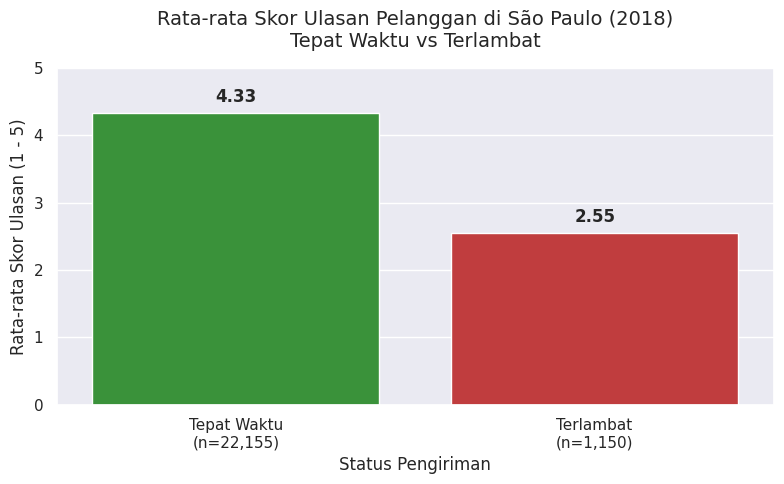

In [ ]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x='delivery_status',
    y='review_score',
    data=q1_df,
    order=['Tepat Waktu', 'Terlambat'],
    palette=['#2ca02c', '#d62728'],
    errorbar=None
)

plt.title("Rata-rata Skor Ulasan Pelanggan di São Paulo (2018)\nTepat Waktu vs Terlambat", fontsize=14, pad=15)
plt.xlabel("Status Pengiriman", fontsize=12)
plt.ylabel("Rata-rata Skor Ulasan (1 - 5)", fontsize=12)
plt.ylim(0, 5)

# Menambahkan angka Rata-rata Skor di atas batang
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',
                xytext=(0, 5),
                textcoords='offset points',
                fontsize=12, fontweight='bold')

# Menghitung jumlah data (n) untuk masing-masing status
count_tepat = len(q1_df[q1_df['delivery_status'] == 'Tepat Waktu'])
count_telat = len(q1_df[q1_df['delivery_status'] == 'Terlambat'])

# Menyisipkan jumlah data (n) ke dalam label Sumbu-X dengan format ribuan
ax.set_xticklabels([
    f"Tepat Waktu\n(n={count_tepat:,})",
    f"Terlambat\n(n={count_telat:,})"
])

plt.tight_layout()
plt.show()

**Insight:** (Opsional)

Berdasarkan grafik di atas, kita dapat menyimpulkan bahwa ketepatan waktu pengiriman memiliki dampak yang sangat krusial terhadap tingkat kepuasan pelanggan di São Paulo:
1. **Kepuasan Tinggi pada Kinerja Normal :** Sebagian besar pesanan (22.151 transaksi) berhasil dikirimkan tepat waktu atau lebih cepat dari estimasi. Kinerja logistik yang baik ini diapresiasi oleh pelanggan dengan memberikan rata-rata skor ulasan yang sangat memuaskan, yaitu **4.33 dari 5.00**.
2. **Penurunan Drastis Akibat Keterlambatan :** Ketika pesanan mengalami keterlambatan (1.150 transaksi), skor kepuasan pelanggan anjlok secara drastis ke angka **2.55 dari 5.00** (turun hampir 2 bintang penuh).
3. **Pentingnya Skala Dampak (Business Impact) :** Meskipun persentase pesanan yang terlambat tergolong kecil (sekitar 5% dari total pesanan di wilayah SP), skor 2.55 tersebut sangat merusak (*destructive*) terhadap reputasi toko secara keseluruhan. Hal ini menegaskan bahwa pelanggan sangat tidak menoleransi keterlambatan logistik, sehingga perbaikan pada rute/mitra ekspedisi yang bermasalah harus menjadi prioritas utama.

### Pertanyaan 2:

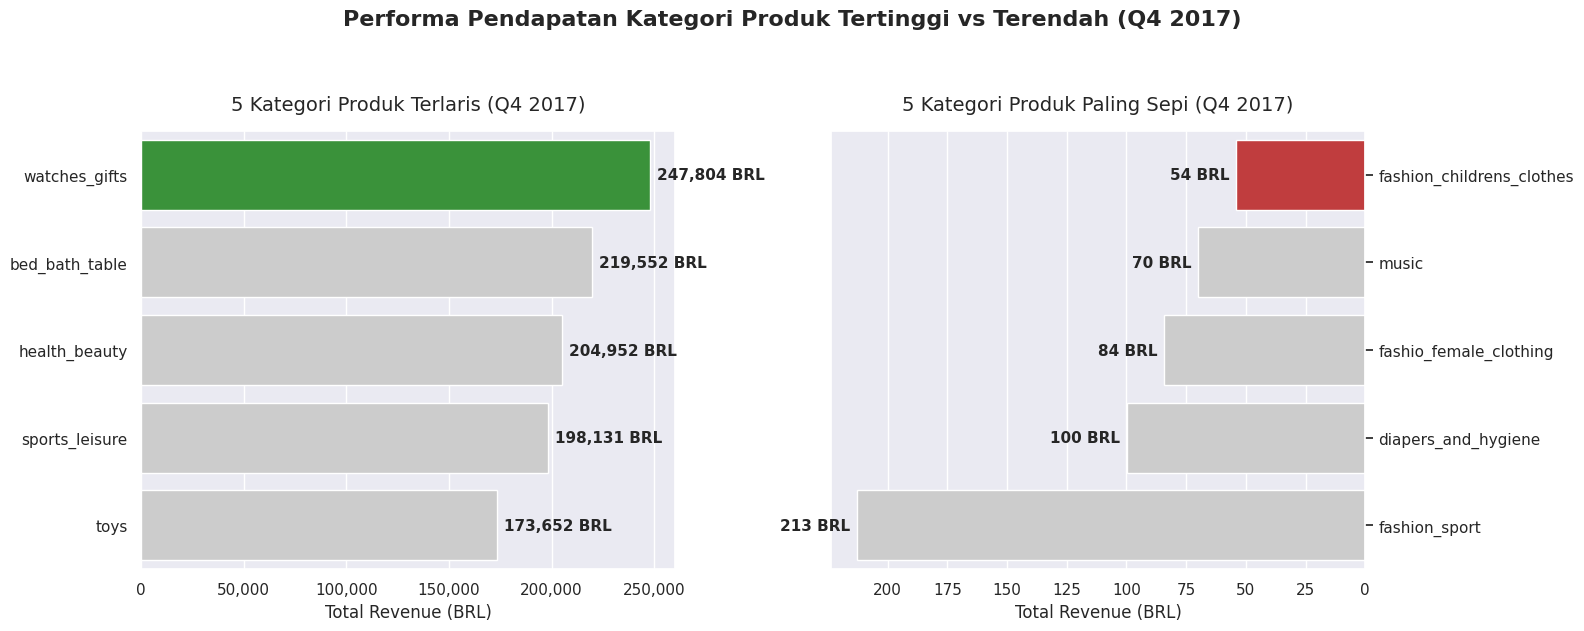

In [7]:
import matplotlib.ticker as ticker

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

colors_top = ["#2ca02c" if i == 0 else "#cccccc" for i in range(5)]
colors_bottom = ["#d62728" if i == 0 else "#cccccc" for i in range(5)]

# Plot Top 5
sns.barplot(x="revenue", y="category", data=revenue_by_cat.head(5), palette=colors_top, ax=ax[0])
ax[0].set_xlabel("Total Revenue (BRL)", fontsize=12)
ax[0].set_ylabel(None)
ax[0].set_title("5 Kategori Produk Terlaris (Q4 2017)", fontsize=14, pad=15)

ax[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x:,.0f}'))

for p in ax[0].patches:
    ax[0].annotate(f"{p.get_width():,.0f} BRL",
                   (p.get_width(), p.get_y() + p.get_height() / 2.),
                   ha='left', va='center',
                   xytext=(5, 0), textcoords='offset points',
                   fontsize=11, fontweight='bold')

# Plot Bottom 5
sns.barplot(x="revenue", y="category", data=revenue_by_cat.tail(5).sort_values(by="revenue", ascending=True), palette=colors_bottom, ax=ax[1])
ax[1].set_xlabel("Total Revenue (BRL)", fontsize=12)
ax[1].set_ylabel(None)
ax[1].invert_xaxis()
ax[1].yaxis.set_label_position("right")
ax[1].yaxis.tick_right()
ax[1].set_title("5 Kategori Produk Paling Sepi (Q4 2017)", fontsize=14, pad=15)

for p in ax[1].patches:
    ax[1].annotate(f"{p.get_width():,.0f} BRL",
                   (p.get_width(), p.get_y() + p.get_height() / 2.),
                   ha='right', va='center',
                   xytext=(-5, 0), textcoords='offset points',
                   fontsize=11, fontweight='bold')

plt.suptitle("Performa Pendapatan Kategori Produk Tertinggi vs Terendah (Q4 2017)", fontsize=16, y=1.05, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

Berdasarkan grafik Performa Pendapatan Kategori Produk di atas, terlihat adanya ketimpangan (disparitas) penjualan yang sangat ekstrem antara produk penyumbang pendapatan terbesar (*cash cow*) dan produk tersepi (*underperforming*) selama periode Kuartal 4 tahun 2017:

1. **Dominasi Produk Hadiah & Gaya Hidup :** Kategori `watches_gifts` (Jam Tangan & Hadiah) memimpin dengan sangat dominan, mencetak total pendapatan tertinggi hingga melampaui **247.000 BRL**. Hal ini sangat relevan dengan perilaku konsumen (*consumer behavior*), di mana Kuartal 4 bertepatan dengan musim liburan akhir tahun (Black Friday, Natal, dan Tahun Baru) sehingga tren pembelian barang untuk hadiah dan gaya hidup/perawatan (seperti `bed_bath_table` dan `health_beauty`) mengalami lonjakan drastis.
2. **Kategori "Mati Suri" (Underperforming) :** Di sisi lain, kategori seperti `fashion_childrens_clothes` (Pakaian Anak) dan `music` tampil sangat mengecewakan. Selama tiga bulan penuh di Q4, produk pakaian anak hanya mampu menghasilkan sekitar **54 BRL**. (Catatan visual: Meskipun batang grafik di sisi kanan terlihat panjang, skala angkanya sangatlah kecil jika dibandingkan dengan grafik di sisi kiri).
3. **Implikasi Bisnis & Efisiensi Gudang :** Kesenjangan yang luar biasa ini memberikan sinyal kuat bagi manajemen inventaris. Perusahaan sangat disarankan untuk mengalokasikan modal pengadaan barang (*restock*) dan anggaran iklan (*marketing budget*) secara agresif pada 5 kategori Top Performer menjelang Q4 tahun berikutnya. Sementara untuk 5 kategori terbawah, perusahaan perlu melakukan evaluasi: apakah akan meluncurkan diskon cuci gudang (*clearance sale*) gila-gilaan, atau menghapus kategori tersebut sepenuhnya jika biaya penyimpanan gudangnya (biaya *inventory*) ternyata lebih mahal daripada pendapatan yang dihasilkannya.

### Pertanyaan 3:

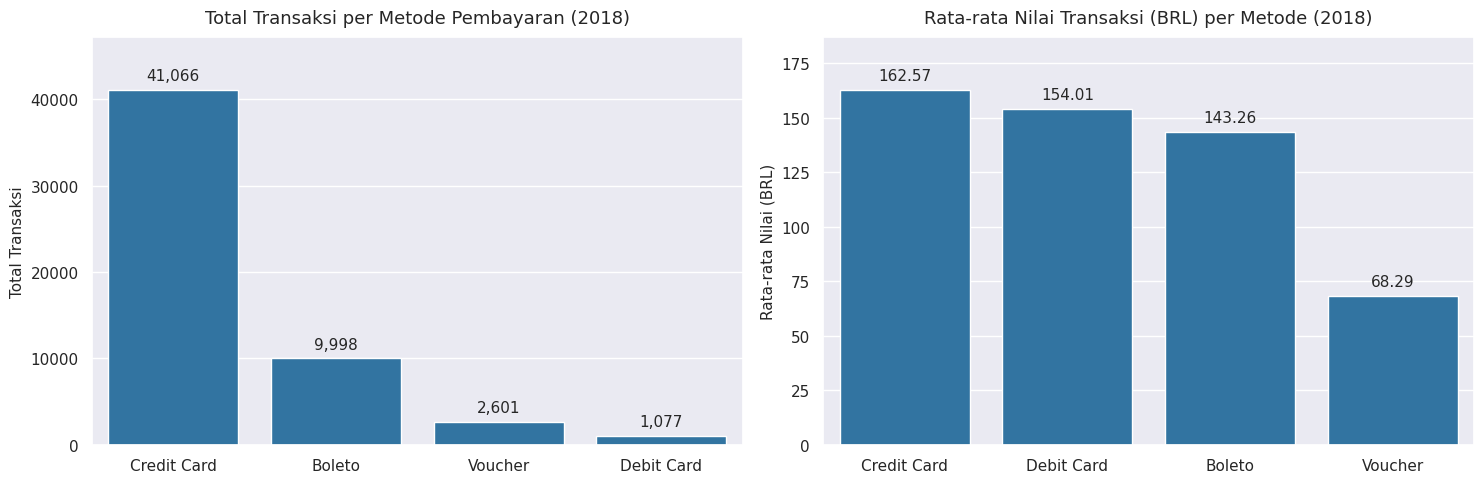

In [8]:
payment_summary['payment_type_clean'] = payment_summary['payment_type'].str.replace('_', ' ').str.title()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

# Total Transaksi
sns.barplot(
    x='payment_type_clean',
    y='total_transactions',
    data=payment_summary,
    color='#1f77b4',
    ax=ax[0]
)
ax[0].set_title('Total Transaksi per Metode Pembayaran (2018)', fontsize=13, pad=10)
ax[0].set_xlabel(None)
ax[0].set_ylabel('Total Transaksi', fontsize=11)

for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():,.0f}",
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='bottom',
                   xytext=(0, 5), textcoords='offset points',
                   fontsize=11)

# Rata-rata Nilai Transaksi
payment_summary_sorted = payment_summary.sort_values(by='avg_payment_value', ascending=False)

sns.barplot(
    x='payment_type_clean',
    y='avg_payment_value',
    data=payment_summary_sorted,
    color='#1f77b4',
    ax=ax[1]
)
ax[1].set_title('Rata-rata Nilai Transaksi (BRL) per Metode (2018)', fontsize=13, pad=10)
ax[1].set_xlabel(None)
ax[1].set_ylabel('Rata-rata Nilai (BRL)', fontsize=11)

for p in ax[1].patches:
    ax[1].annotate(f"{p.get_height():.2f}",
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='bottom',
                   xytext=(0, 5), textcoords='offset points',
                   fontsize=11)

ax[0].set_ylim(0, payment_summary['total_transactions'].max() * 1.15)
ax[1].set_ylim(0, payment_summary['avg_payment_value'].max() * 1.15)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)

Berdasarkan visualisasi preferensi metode pembayaran selama tahun 2018, kita dapat memetakan perilaku transaksi pelanggan ke dalam beberapa poin strategis:

1. **Dominasi Mutlak Kartu Kredit (Volume & Value):** Kartu Kredit (*Credit Card*) adalah tulang punggung pendapatan perusahaan. Metode ini tidak hanya mendominasi secara volume (41.066 transaksi, empat kali lipat lebih banyak dari peringkat kedua), tetapi juga mendorong pelanggan untuk mengeluarkan uang paling banyak per transaksinya dengan *Average Order Value* (AOV) tertinggi, yakni **162.57 BRL**. Hal ini kemungkinan besar didorong oleh adanya fasilitas cicilan (*installments*) yang meringankan beban psikologis pelanggan saat membeli barang mahal.
2. **Potensi Tersembunyi (*Hidden Gem*) Kartu Debit:** Terdapat temuan yang sangat menarik pada metode Kartu Debit. Meskipun popularitasnya paling rendah (berada di posisi buncit dengan hanya 1.077 transaksi), pengguna Kartu Debit ternyata memiliki daya beli yang sangat kuat. Rata-rata nilai transaksi Kartu Debit mencapai **154.01 BRL**, menempati posisi kedua tertinggi dan mengalahkan Boleto.
3. **Karakteristik Boleto dan Voucher:** Boleto (metode cetak tiket pembayaran luring) mengamankan posisi kedua dalam frekuensi penggunaan, membuktikan bahwa metode tradisional ini masih sangat esensial bagi demografi pelanggan yang tidak memiliki akses perbankan digital. Sementara itu, pembayaran menggunakan Voucher mencatatkan AOV yang sangat rendah (hanya **68.29 BRL**), mengindikasikan bahwa voucher umumnya hanya dimanfaatkan untuk menebus barang-barang murah atau sebagai pelengkap sisa pembayaran.

## Conclusion & Recommendation

* **Conclusion pertanyaan 1 :** Keterlambatan pengiriman memiliki dampak negatif yang sangat fatal terhadap kepuasan pelanggan di wilayah São Paulo (2018). Pesanan yang tiba tepat waktu mendapatkan apresiasi berupa rata-rata skor ulasan yang memuaskan (4.33 dari 5.00), sedangkan pesanan yang terlambat menyebabkan tingkat kepuasan anjlok secara drastis menjadi 2.55.
* **Conclusion pertanyaan 2 :** Terdapat ketimpangan performa penjualan yang ekstrem antar kategori produk pada Kuartal 4 tahun 2017 (musim liburan). Kategori barang hadiah dan gaya hidup, dipimpin oleh *watches_gifts*, sangat mendominasi pasar dengan pendapatan lebih dari 247.000 BRL. Sebaliknya, kategori *fashion_childrens_clothes* menjadi produk yang paling diabaikan pelanggan.
* **Conclusion pertanyaan 3 :** Kartu Kredit (*Credit Card*) adalah urat nadi utama transaksi pelanggan selama tahun 2018, mendominasi frekuensi (lebih dari 41 ribu transaksi) dan menghasilkan rata-rata nilai pesanan (AOV) tertinggi sebesar 162.57 BRL. Selain itu, Kartu Debit menunjukkan pola *hidden gem*: meskipun frekuensi penggunaannya paling sepi, pelanggannya memiliki daya beli (AOV) tertinggi kedua (154.01 BRL) setelah Kartu Kredit.

**Rekomendasi Action Item:**
* **Restrukturisasi Operasional Logistik (SP) :** Manajemen harus melakukan evaluasi ketat terhadap mitra ekspedisi yang beroperasi di wilayah São Paulo dan memperbaiki algoritma estimasi waktu tiba (ETA) di aplikasi. Memprioritaskan ketepatan waktu adalah kunci utama untuk memulihkan dan mempertahankan skor ulasan toko di atas bintang 4.
* **Optimalisasi Inventaris dan Anggaran Marketing Q4 :** Menjelang Kuartal 4 tahun berikutnya, tim *Procurement* harus memusatkan modal pengadaan barang pada kategori unggulan (seperti *Watches & Gifts* dan *Health & Beauty*). Untuk produk dengan performa terburuk, segera luncurkan program *clearance sale* (cuci gudang) gila-gilaan untuk membebaskan ruang gudang (*inventory cost*), atau pertimbangkan untuk menghentikan penjualannya secara permanen.
* **Program Promosi Berbasis Metode Pembayaran :** Karena pelanggan yang menggunakan instrumen perbankan (Kartu Kredit dan Kartu Debit) terbukti berani membelanjakan nominal yang jauh lebih besar, perusahaan perlu memperkuat kerja sama dengan Bank. Tawarkan promo "Cicilan 0% Eksklusif" atau "Diskon Spesial Kartu Debit" untuk merangsang lebih banyak pelanggan melakukan *checkout* pada barang-barang bernilai tinggi.